# Advanced Knowledge Distillation Techniques

This notebook covers advanced methods and optimizations for knowledge distillation, building on the basics from previous notebooks. We'll explore multi-teacher distillation, self-distillation, and more.

The examples run on MNIST.
Teachers are trained on the full 54,000 image training split, students only see a 5,000 image subset.
Limiting the student's data leaves room for the teacher to help: the MNIST experiment found no gain from distillation with all 54,000 images and a consistent gain with 1,000.

## Setup

In [1]:
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cpu


Library versions and hardware, for reproducing the numbers below.

In [2]:
import platform
print(f"python {platform.python_version()}, torch {torch.__version__}, numpy {np.__version__}, pandas {pd.__version__}")
print(f"platform: {platform.platform()}, {os.cpu_count()} logical cpus, torch threads: {torch.get_num_threads()}")

python 3.12.15, torch 2.14.1+cpu, numpy 2.5.4, pandas 3.0.6
platform: Windows-10-10.0.19045-SP0, 16 logical cpus, torch threads: 8


### Reproducibility

`SEED` fixes the data split, the teachers and the demos, each arm of the comparison at the end is trained once per entry of `SEEDS`.

In [3]:
SEED = 0
SEEDS = [0, 1, 2]
torch.manual_seed(SEED)
# deterministic kernels, so a rerun with the same seed gives the same numbers on this machine
torch.use_deterministic_algorithms(True)
# downloads land outside the repository, set KD_DATA_DIR to put them somewhere else
DATA_DIR = os.environ.get('KD_DATA_DIR', os.path.join(os.path.expanduser('~'), '.cache', 'kd-data'))

## Data

MNIST flattened to 784 standardised values, 6,000 training images held out for validation, and a 5,000 image student subset with 500 images per class.

In [4]:
def load_mnist(train):
    # the whole set fits in memory, so the tensors are built once instead of decoding images per batch
    raw = datasets.MNIST(DATA_DIR, train=train, download=True)
    x = (raw.data.float() / 255.0 - 0.1307) / 0.3081
    return x.view(len(x), -1), raw.targets.clone()

The validation split and the class balanced student subset.

In [5]:
all_X, all_y = load_mnist(train=True)
perm = torch.randperm(len(all_X), generator=torch.Generator().manual_seed(SEED))
val_X, val_y = all_X[perm[:6000]], all_y[perm[:6000]]
full_X, full_y = all_X[perm[6000:]], all_y[perm[6000:]]

class_rng = np.random.default_rng(SEED)
small_idx = np.concatenate([class_rng.choice(np.flatnonzero(full_y.numpy() == c), 500, replace=False) for c in range(10)])
train_X, train_y = full_X[small_idx], full_y[small_idx]

Batches for the teachers, the students and validation.

In [6]:
teacher_loader = DataLoader(TensorDataset(full_X, full_y), batch_size=128, shuffle=True)
train_loader = DataLoader(TensorDataset(train_X, train_y), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(val_X, val_y), batch_size=1000)
print(f"teacher training images: {len(full_X)}, student training images: {len(train_X)}, validation images: {len(val_X)}")

teacher training images: 54000, student training images: 5000, validation images: 6000


Accuracy on the validation set unless another loader is passed.

In [7]:
def evaluate(model, loader=val_loader):
    # accuracy with any dropout off, argmax of the logits does not depend on the temperature
    model.eval()
    correct = 0
    with torch.no_grad():
        for batch_X, batch_y in loader:
            correct += (model(batch_X.to(device)).argmax(dim=1) == batch_y.to(device)).sum().item()
    return 100 * correct / len(loader.dataset)

## Technique 1: Multi-Teacher Distillation

Instead of learning from one teacher, the student learns from multiple teachers with different strengths. This creates an ensemble effect.

In [8]:
def multi_teacher_distillation_loss(student_logits, teacher_logits_list, labels, temperature=3.0, alpha=0.7, teacher_weights=None):
    """
    distill from several teachers by matching a weighted average of their softened outputs
    
    args:
        student_logits: raw student outputs
        teacher_logits_list: raw outputs from each teacher
        labels: ground truth class indices
        temperature: softening parameter
        alpha: weight on the distillation term, 1 - alpha goes to the label term
        teacher_weights: how much each teacher is trusted, should sum to 1 (default: equal weights)
    """
    num_teachers = len(teacher_logits_list)
    
    if teacher_weights is None:
        teacher_weights = [1.0 / num_teachers] * num_teachers
    
    # averaging probabilities rather than logits keeps the ensemble target a proper distribution
    ensemble_soft = torch.zeros_like(
        F.softmax(teacher_logits_list[0] / temperature, dim=-1))
    
    for teacher_logits, weight in zip(teacher_logits_list, teacher_weights):
        soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
        ensemble_soft += weight * soft_teacher
    
    soft_student = F.log_softmax(student_logits / temperature, dim=-1)
    
    distill_loss = F.kl_div(
        soft_student, ensemble_soft, reduction='batchmean') * (temperature ** 2)
    student_loss = F.cross_entropy(student_logits, labels)
    
    return alpha * distill_loss + (1 - alpha) * student_loss

A one hidden layer MLP serves as both teacher and student in the demos.

In [9]:
# one hidden layer mlp, the width is the only thing that differs between teachers and student
class SimpleModel(nn.Module):
    def __init__(self, input_size=784, hidden_size=256, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes))
    
    def forward(self, x):
        return self.net(x)

Three untrained teachers of different widths and a smaller student.

In [10]:
teacher1 = SimpleModel(hidden_size=512).to(device)
teacher2 = SimpleModel(hidden_size=384).to(device)
teacher3 = SimpleModel(hidden_size=256).to(device)
student = SimpleModel(hidden_size=128).to(device)

The loss runs and returns a scalar with unequal teacher weights.

In [11]:
# smoke test with untrained teachers, the loss value itself means nothing
dummy_input = torch.randn(4, 784).to(device)
dummy_labels = torch.randint(0, 10, (4,)).to(device)

with torch.no_grad():
    t1_out = teacher1(dummy_input)
    t2_out = teacher2(dummy_input)
    t3_out = teacher3(dummy_input)

s_out = student(dummy_input)

loss = multi_teacher_distillation_loss(
    s_out, [t1_out, t2_out, t3_out], dummy_labels,
    teacher_weights=[0.5, 0.3, 0.2] ) # unequal weights trust the first teacher most

print(f"Multi-teacher distillation loss: {loss.item():.4f}")
print("\nThis combines knowledge from 3 teachers with weights [0.5, 0.3, 0.2]")

Multi-teacher distillation loss: 0.7705

This combines knowledge from 3 teachers with weights [0.5, 0.3, 0.2]


## Technique 2: Progressive Distillation

Gradually change temperature and alpha during training - start easy, get harder.

In [12]:
# anneal from soft to sharp targets, progress runs from 0 on the first epoch to 1 on the last
def progressive_temperature_schedule(epoch, num_epochs, start_temp=5.0, end_temp=1.0):
    progress = epoch / max(num_epochs - 1, 1)
    return start_temp * (1 - progress) + end_temp * progress


# shift weight from the teacher toward the true labels as training goes on
def progressive_alpha_schedule(epoch, num_epochs, start_alpha=0.9, end_alpha=0.5):
    progress = epoch / max(num_epochs - 1, 1)
    return start_alpha * (1 - progress) + end_alpha * progress

Both schedules over a 20 epoch run.

In [13]:
epochs = np.arange(0, 20)
temps = [progressive_temperature_schedule(e, 20) for e in epochs]
alphas = [progressive_alpha_schedule(e, 20) for e in epochs]

Plot both schedules.

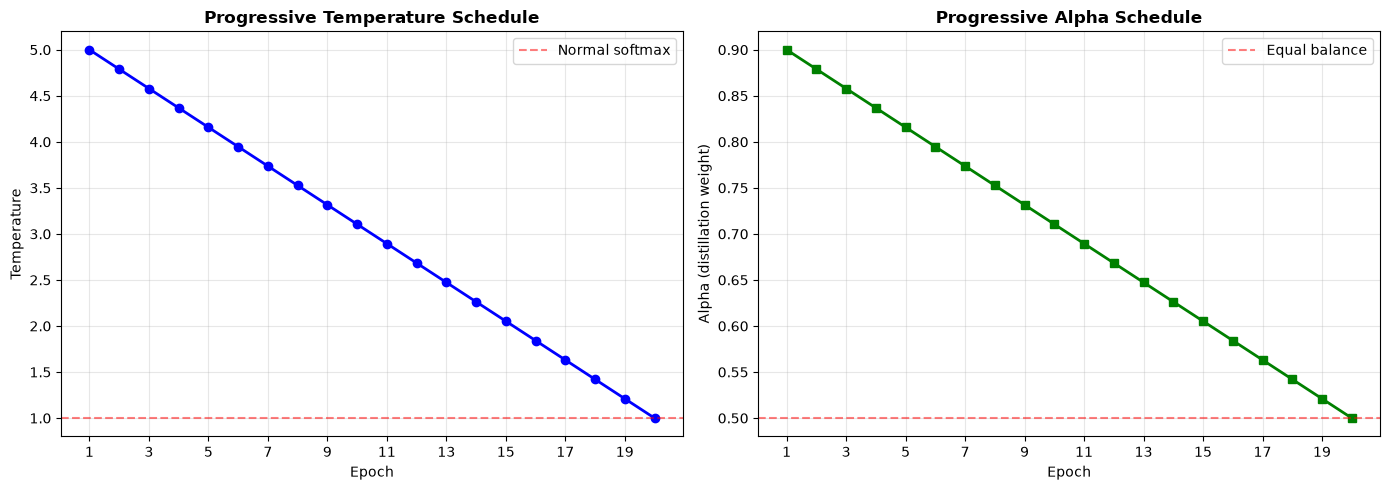

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# the schedules take a 0 based epoch index, the axis shows epochs counted from 1
axes[0].plot(epochs + 1, temps, marker='o', linewidth=2, color='blue')
axes[0].set_title('Progressive Temperature Schedule', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Temperature')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=1.0, color='r', linestyle='--', alpha=0.5, label='Normal softmax')
axes[0].legend()

axes[1].plot(epochs + 1, alphas, marker='s', linewidth=2, color='green')
axes[1].set_title('Progressive Alpha Schedule', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Alpha (distillation weight)')
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Equal balance')
axes[1].legend()

for ax in axes:
    ax.set_xticks(range(1, len(epochs) + 1, 2))
plt.tight_layout()
plt.show()

What the two schedules are meant to do.

In [15]:
print("Early training: High temperature (soft, easy) + High alpha (rely on teacher)")
print("Late training:  Low temperature (sharp, hard) + Low alpha (rely on labels)")

Early training: High temperature (soft, easy) + High alpha (rely on teacher)
Late training:  Low temperature (sharp, hard) + Low alpha (rely on labels)


### Progressive Distillation Training Loop

In [16]:
# train with progressive temperature and alpha schedules
def train_progressive_distillation(student, teacher, train_loader, num_epochs=15):
    optimizer = optim.Adam(student.parameters(), lr=0.001)
    teacher.eval()
    
    temp_history = []
    alpha_history = []
    loss_history = []
    
    print("Progressive Distillation Training:")
    
    for epoch in range(num_epochs):
        temperature = progressive_temperature_schedule(epoch, num_epochs)
        alpha = progressive_alpha_schedule(epoch, num_epochs)
        
        temp_history.append(temperature)
        alpha_history.append(alpha)
        
        student.train()
        epoch_loss = 0
        
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            
            with torch.no_grad():
                teacher_logits = teacher(batch_X)
            
            student_logits = student(batch_X)
            
            soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
            soft_student = F.log_softmax(student_logits / temperature, dim=-1)
            
            distill_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (temperature ** 2)
            student_loss = F.cross_entropy(student_logits, batch_y)
            
            total_loss = alpha * distill_loss + (1 - alpha) * student_loss
            
            total_loss.backward()
            optimizer.step()
            
            epoch_loss += total_loss.item()
        
        avg_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_loss)
        
        if (epoch + 1) % 3 == 0:
            print(f"Epoch {epoch+1:2d} | T={temperature:.2f} | α={alpha:.2f} | Loss={avg_loss:.4f}")
    
    return loss_history, temp_history, alpha_history

Train a teacher on the full training split, then distill into a student with the schedules.

In [17]:
# the teacher has to be trained before it can teach
print("Pre-training teacher on the full training split")
teacher = SimpleModel(hidden_size=512).to(device)
optimizer = optim.Adam(teacher.parameters(), lr=0.001)
teacher.train()
for _ in range(5):
    for batch_X, batch_y in teacher_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = teacher(batch_X)
        loss = F.cross_entropy(outputs, batch_y)
        loss.backward()
        optimizer.step()
teacher.eval()
print(f"Teacher validation accuracy: {evaluate(teacher):.2f}%")

Pre-training teacher on the full training split


Teacher validation accuracy: 97.30%


Progressive distillation on the 5,000 image subset.

In [18]:
student = SimpleModel(hidden_size=128).to(device)
losses, temps, alphas = train_progressive_distillation(student, teacher, train_loader)
print(f"Progressive student validation accuracy: {evaluate(student):.2f}%")

Progressive Distillation Training:


Epoch  3 | T=4.43 | α=0.84 | Loss=2.2523


Epoch  6 | T=3.57 | α=0.76 | Loss=0.8875


Epoch  9 | T=2.71 | α=0.67 | Loss=0.3512


Epoch 12 | T=1.86 | α=0.59 | Loss=0.1211


Epoch 15 | T=1.00 | α=0.50 | Loss=0.0373
Progressive student validation accuracy: 94.33%


## Technique 3: Feature-Based Distillation

Match intermediate layer representations, not just final outputs.

In [19]:
class FeatureTeacher(nn.Module):
    """teacher that can also return its hidden layer activations"""
    def __init__(self, input_size=784, num_classes=10):
        super().__init__()
        self.layer1 = nn.Sequential(nn.Linear(input_size, 512), nn.ReLU())
        self.layer2 = nn.Sequential(nn.Linear(512, 256), nn.ReLU())
        self.layer3 = nn.Linear(256, num_classes)
    
    def forward(self, x, return_features=False):
        feat1 = self.layer1(x)
        feat2 = self.layer2(feat1)
        output = self.layer3(feat2)
        
        if return_features:
            return output, [feat1, feat2]
        return output

The student also returns its features, projected to the teacher's widths so they can be compared.

In [20]:
# student that can also return its hidden activations, projected to the teacher's widths
class FeatureStudent(nn.Module):
    
    def __init__(self, input_size=784, num_classes=10):
        super().__init__()
        self.layer1 = nn.Sequential(nn.Linear(input_size, 256), nn.ReLU())
        self.layer2 = nn.Sequential(nn.Linear(256, 128), nn.ReLU())
        self.layer3 = nn.Linear(128, num_classes)
        
        # learned projections let mse compare features of different widths, as in fitnets hints
        self.proj1 = nn.Linear(256, 512)
        self.proj2 = nn.Linear(128, 256)
    
    def forward(self, x, return_features=False):
        feat1 = self.layer1(x)
        feat2 = self.layer2(feat1)
        output = self.layer3(feat2)
        
        if return_features:
            proj_feat1 = self.proj1(feat1)
            proj_feat2 = self.proj2(feat2)
            return output, [proj_feat1, proj_feat2]
        return output

The combined loss: output distillation, feature matching and the labels.

In [21]:
def feature_distillation_loss(student_outputs, student_features,teacher_outputs, teacher_features, labels, temperature=3.0, alpha=0.5, beta=0.3):
    """
    output distillation plus feature matching on hidden layers
    
    args:
        alpha: weight on output distillation
        beta: weight on feature matching
        1 - alpha - beta goes to the label term
    """
    # the teacher only provides targets, detaching keeps every gradient out of it
    teacher_outputs = teacher_outputs.detach()
    teacher_features = [f.detach() for f in teacher_features]

    # output term: the usual softened kl, times t^2
    soft_teacher = F.softmax(teacher_outputs / temperature, dim=-1)
    soft_student = F.log_softmax(student_outputs / temperature, dim=-1)
    output_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (temperature ** 2)
    
    # feature term: mse between projected student features and teacher features
    feature_loss = 0
    for s_feat, t_feat in zip(student_features, teacher_features):
        feature_loss += F.mse_loss(s_feat, t_feat)
    feature_loss /= len(student_features)  # average over layers
    
    student_loss = F.cross_entropy(student_outputs, labels)
    
    total_loss = alpha * output_loss + beta * feature_loss + (1 - alpha - beta) * student_loss
    
    return total_loss, output_loss, feature_loss, student_loss

One forward pass through both models and the combined loss.

In [22]:
# smoke test, both models untrained
feat_teacher = FeatureTeacher().to(device)
feat_student = FeatureStudent().to(device)

dummy_input = torch.randn(8, 784).to(device)
dummy_labels = torch.randint(0, 10, (8,)).to(device)

t_out, t_feats = feat_teacher(dummy_input, return_features=True)
s_out, s_feats = feat_student(dummy_input, return_features=True)

total, out_loss, feat_loss, stud_loss = feature_distillation_loss(s_out, s_feats, t_out, t_feats, dummy_labels)

In [23]:
print("Feature-Based Distillation Loss Breakdown:")
print(f"Output Distillation Loss:{out_loss.item():.4f} (weight: 0.5)")
print(f"Feature Matching Loss:{feat_loss.item():.4f} (weight: 0.3)")
print(f"Student CE Loss:{stud_loss.item():.4f} (weight: 0.2)")
print(f"Total Loss:{total.item():.4f}")
print(f"\nNumber of feature layers matched: {len(s_feats)}")

Feature-Based Distillation Loss Breakdown:
Output Distillation Loss:0.0096 (weight: 0.5)
Feature Matching Loss:0.1402 (weight: 0.3)
Student CE Loss:2.3267 (weight: 0.2)
Total Loss:0.5122

Number of feature layers matched: 2


## Technique 4: Self-Distillation

The model learns from its own previous predictions, no separate teacher needed.
Each training example's logits from the previous epoch become its soft target in the current epoch, in the spirit of Kim et al. (2021), "Self-Knowledge Distillation with Progressive Refinement of Targets".
The first epoch has no stored targets yet and uses the labels alone.

In [24]:
# self-distillation: the model's own logits from the previous epoch act as the teacher
def self_distillation_epoch(model, train_loader, previous_logits, has_previous, optimizer, temperature=3.0, alpha=0.7):
    model.train()
    epoch_loss = 0
    distilled_batches = 0

    for batch_X, batch_y, batch_idx in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()

        current_logits = model(batch_X)

        # targets are stored per example, so they follow each example through the shuffling
        if has_previous[batch_idx].all():
            teacher_logits = previous_logits[batch_idx].to(device)

            soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
            soft_student = F.log_softmax(current_logits / temperature, dim=-1)

            distill_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (temperature ** 2)
            student_loss = F.cross_entropy(current_logits, batch_y)

            loss = alpha * distill_loss + (1 - alpha) * student_loss
            distilled_batches += 1
        else:
            loss = F.cross_entropy(current_logits, batch_y)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        # each example is seen once per epoch, so this is next epoch's target for it
        previous_logits[batch_idx] = current_logits.detach().cpu()
        has_previous[batch_idx] = True

    return epoch_loss / len(train_loader), distilled_batches

Self-distillation needs to know which examples are in each batch.

In [25]:
# the loader also yields each example's index, which is how its stored logits are found again
indexed_loader = DataLoader(TensorDataset(train_X, train_y, torch.arange(len(train_X))), batch_size=64, shuffle=True)

Ten epochs of self-distillation on the student subset.

In [26]:
print("Self-Distillation Training:")

model = SimpleModel(hidden_size=128).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
previous_logits = torch.zeros(len(train_X), 10)
has_previous = torch.zeros(len(train_X), dtype=torch.bool)

losses = []
for epoch in range(10):
    loss, distilled_batches = self_distillation_epoch(model, indexed_loader, previous_logits, has_previous, optimizer)
    losses.append(loss)

    if (epoch + 1) % 2 == 0:
        print(f"Epoch {epoch+1:2d} | Loss: {loss:.4f} | "
              f"batches trained on stored targets: {distilled_batches} of {len(indexed_loader)}")
print(f"Self-distilled model validation accuracy: {evaluate(model):.2f}%")

Self-Distillation Training:


Epoch  2 | Loss: 0.5897 | batches trained on stored targets: 79 of 79


Epoch  4 | Loss: 0.1145 | batches trained on stored targets: 79 of 79


Epoch  6 | Loss: 0.0930 | batches trained on stored targets: 79 of 79


Epoch  8 | Loss: 0.0823 | batches trained on stored targets: 79 of 79


Epoch 10 | Loss: 0.0715 | batches trained on stored targets: 79 of 79
Self-distilled model validation accuracy: 92.63%


The loss per epoch.

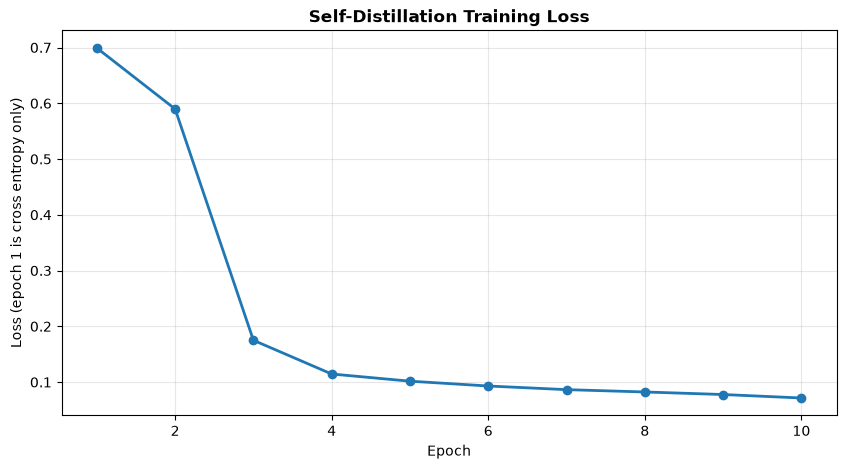

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(losses) + 1), losses, marker='o', linewidth=2)
plt.title('Self-Distillation Training Loss', fontweight='bold', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Loss (epoch 1 is cross entropy only)')
plt.grid(True, alpha=0.3)
plt.show()

## Practical Optimization Tips for Large Models

When working with LLMs and large models:

### Gradient accumulation

Summing the gradients of several small batches, each loss divided by the number of batches, gives the gradient of one large batch while only one small batch is in memory at a time.
The check below compares the two on one batch of 64, split into 4 micro batches of 16.

In [28]:
def accumulated_gradients(model, teacher, batch_X, batch_y, accumulation_steps, temperature=3.0, alpha=0.7):
    model.zero_grad()
    for x_chunk, y_chunk in zip(batch_X.chunk(accumulation_steps), batch_y.chunk(accumulation_steps)):
        with torch.no_grad():
            teacher_logits = teacher(x_chunk)
        loss = multi_teacher_distillation_loss(model(x_chunk), [teacher_logits], y_chunk, temperature, alpha)
        # equal chunks and a division by their number make the summed gradients the full batch mean
        (loss / accumulation_steps).backward()
    return [p.grad.clone() for p in model.parameters()]

Compare one batch of 64 against four accumulated micro batches.

In [29]:
accum_model = SimpleModel().to(device)
batch_X, batch_y = next(iter(train_loader))
batch_X, batch_y = batch_X.to(device), batch_y.to(device)
full_batch = accumulated_gradients(accum_model, teacher, batch_X, batch_y, accumulation_steps=1)
four_micro_batches = accumulated_gradients(accum_model, teacher, batch_X, batch_y, accumulation_steps=4)
max_diff = max((a - b).abs().max().item() for a, b in zip(full_batch, four_micro_batches))
print(f"largest difference between the two gradients: {max_diff:.2e}")

largest difference between the two gradients: 1.27e-07


### Selective distillation

For sequence models, the distillation loss can be restricted to the positions that matter, such as answer tokens, and padding left out.
Both losses below are a per token KL times `T^2`, averaged over different sets of positions, so they are directly comparable.

In [30]:
def per_token_kl(student_logits, teacher_logits, temperature=3.0):
    # kl summed over the vocabulary, leaving one value per position
    return F.kl_div(F.log_softmax(student_logits / temperature, dim=-1),
                    F.softmax(teacher_logits / temperature, dim=-1), reduction='none').sum(dim=-1)

The masked loss, averaged over the positions the mask keeps.

In [31]:
# selective distillation: only positions that matter (answer tokens, not padding) contribute
def selective_distillation_loss(student_logits, teacher_logits, mask, temperature=3.0):
    """
    distillation loss averaged over the positions the mask keeps,
    for llms: answer tokens count, padding does not

    args:
        mask: binary mask (1 = keep, 0 = ignore), one value per position
    """
    kl = per_token_kl(student_logits, teacher_logits, temperature)
    return (kl * mask).sum() / mask.sum() * temperature ** 2

Random logits with three padding positions per sequence.

In [32]:
# random logits, the first three positions play the role of padding
torch.manual_seed(0)
batch_size, seq_len, vocab_size = 4, 10, 100
dummy_student = torch.randn(batch_size, seq_len, vocab_size)
dummy_teacher = torch.randn(batch_size, seq_len, vocab_size)

mask = torch.ones(batch_size, seq_len)
mask[:, :3] = 0

The loss over all positions, the kept positions and the padding alone.

In [33]:
full_loss = per_token_kl(dummy_student, dummy_teacher).mean() * 3.0 ** 2
selective_loss = selective_distillation_loss(dummy_student, dummy_teacher, mask)
padding_only = selective_distillation_loss(dummy_student, dummy_teacher, 1 - mask)

print("Selective Distillation:")
print(f"all positions: {full_loss.item():.4f}")
print(f"kept positions only: {selective_loss.item():.4f}")
print(f"padding positions only: {padding_only.item():.4f}")
print(f"\nMask pattern: {mask[0].numpy()}")
print("with random logits every position looks alike, so the three numbers are close: the mask changes which positions train the student, not the scale of the loss")

Selective Distillation:
all positions: 1.0161
kept positions only: 1.0201
padding positions only: 1.0066

Mask pattern: [0. 0. 0. 1. 1. 1. 1. 1. 1. 1.]
with random logits every position looks alike, so the three numbers are close: the mask changes which positions train the student, not the scale of the loss


## Comparing the Techniques

Every technique trains the same student, a `FeatureStudent` (its projection layers only matter in the feature arm), on the same 5,000 images for 15 epochs, three seeds each.
Within a seed every arm starts from the same weights and sees the same batches, so differences come from the loss alone.
Each arm uses `T = 4` and `alpha = 0.7` unless its technique says otherwise: progressive distillation follows its schedules, feature distillation uses `alpha = 0.5`, `beta = 0.3`.
These settings were not tuned, so the comparison shows how each technique behaves out of the box, not its best case.

The teachers are trained on all 54,000 training images first and then frozen.

In [34]:
def freeze(model):
    # eval mode and no gradients: a frozen teacher only ever provides targets
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model

Teachers are trained on hard labels for 5 epochs, then frozen.

In [35]:
def train_teacher(model, epochs=5):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    model.train()
    for _ in range(epochs):
        for batch_X, batch_y in teacher_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            F.cross_entropy(model(batch_X), batch_y).backward()
            optimizer.step()
    return freeze(model)

Train the feature teacher and a second simple teacher, the progressive section's teacher is the third.

In [36]:
torch.manual_seed(SEED)
main_teacher = train_teacher(FeatureTeacher().to(device))
second_teacher = train_teacher(SimpleModel(hidden_size=384).to(device))
# the progressive section's teacher joins the ensemble, frozen like the others
ensemble = [main_teacher, freeze(teacher), second_teacher]
for name, model in [('feature teacher (512, 256)', main_teacher), ('simple teacher (512)', teacher), ('simple teacher (384)', second_teacher)]:
    print(f"{name}: validation accuracy {evaluate(model):.2f}%")

feature teacher (512, 256): validation accuracy 96.97%
simple teacher (512): validation accuracy 97.30%
simple teacher (384): validation accuracy 97.25%


The loss each arm trains on.

In [37]:
def arm_loss(arm, model, batch_X, batch_y, batch_idx, epoch, epochs, memory):
    # memory holds the self-distillation targets, one row of logits per training example
    if arm == 'control':
        return F.cross_entropy(model(batch_X), batch_y)
    if arm == 'feature':
        out, feats = model(batch_X, return_features=True)
        t_out, t_feats = main_teacher(batch_X, return_features=True)
        return feature_distillation_loss(out, feats, t_out, t_feats, batch_y, temperature=4.0)[0]
    out = model(batch_X)
    if arm == 'self':
        previous, seen = memory
        targets = previous[batch_idx].to(device)
        loss = (multi_teacher_distillation_loss(out, [targets], batch_y, 4.0, 0.7)
                if seen[batch_idx].all() else F.cross_entropy(out, batch_y))
        previous[batch_idx] = out.detach().cpu()
        seen[batch_idx] = True
        return loss
    if arm == 'progressive':
        temperature = progressive_temperature_schedule(epoch, epochs)
        alpha = progressive_alpha_schedule(epoch, epochs)
        return multi_teacher_distillation_loss(out, [main_teacher(batch_X)], batch_y, temperature, alpha)
    teachers = ensemble if arm == 'multi-teacher' else [main_teacher]
    return multi_teacher_distillation_loss(out, [m(batch_X) for m in teachers], batch_y, 4.0, 0.7)

One training run for one arm and one seed.

In [38]:
def train_arm(arm, seed, epochs=15):
    torch.manual_seed(seed)
    model = FeatureStudent().to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    # the same generator seed gives every arm the same batches
    loader = DataLoader(TensorDataset(train_X, train_y, torch.arange(len(train_X))), batch_size=64,
                        shuffle=True, generator=torch.Generator().manual_seed(seed))
    memory = (torch.zeros(len(train_X), 10), torch.zeros(len(train_X), dtype=torch.bool))
    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y, batch_idx in loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            arm_loss(arm, model, batch_X, batch_y, batch_idx, epoch, epochs, memory).backward()
            optimizer.step()
    return model

All six arms over the three seeds.

In [39]:
ARMS = ['control', 'standard', 'multi-teacher', 'progressive', 'feature', 'self']
students = {arm: [train_arm(arm, seed) for seed in SEEDS] for arm in ARMS}

The test set is read here for the first time.

In [40]:
test_X, test_y = load_mnist(train=False)
test_loader = DataLoader(TensorDataset(test_X, test_y), batch_size=1000)
test_acc = pd.DataFrame({arm: [evaluate(m, test_loader) for m in models] for arm, models in students.items()},
                        index=pd.Index(SEEDS, name='seed'))
print("Test accuracy (%) per seed:")
print(test_acc.round(2).to_string())

Test accuracy (%) per seed:
      control  standard  multi-teacher  progressive  feature   self
seed                                                               
0       95.25     96.00          96.72        95.69    96.24  94.98
1       95.16     95.99          96.84        95.76    95.95  94.66
2       95.15     96.33          97.06        96.21    96.55  95.03


Mean and standard deviation over the seeds, and each arm's paired difference to the control.

In [41]:
rows = []
for arm in ARMS:
    diff = test_acc[arm] - test_acc['control']
    p = stats.ttest_rel(test_acc[arm], test_acc['control']).pvalue if arm != 'control' else float('nan')
    rows.append({'technique': arm, 'test acc mean (%)': test_acc[arm].mean(), 'std': test_acc[arm].std(),
                 'minus control (pp)': diff.mean(), 'diff std': diff.std(), 'paired t test p': p})
comparison = pd.DataFrame(rows).round(3)
print(f"main teacher test accuracy: {evaluate(main_teacher, test_loader):.2f}%, "
      f"the other two ensemble members: {evaluate(teacher, test_loader):.2f}%, {evaluate(second_teacher, test_loader):.2f}%")
print(comparison.to_string(index=False))

main teacher test accuracy: 97.23%, the other two ensemble members: 97.59%, 97.68%
    technique  test acc mean (%)   std  minus control (pp)  diff std  paired t test p
      control             95.187 0.055               0.000     0.000              NaN
     standard             96.107 0.193               0.920     0.229            0.020
multi-teacher             96.873 0.172               1.687     0.220            0.006
  progressive             95.887 0.282               0.700     0.322            0.064
      feature             96.247 0.300               1.060     0.311            0.028
         self             94.890 0.201              -0.297     0.191            0.115


### What the comparison shows

With 5,000 training images the control student reached 95.19 ± 0.06% test accuracy (mean ± std over 3 seeds).
Standard distillation from the frozen feature teacher added 0.92 ± 0.23 percentage points (paired t test p = 0.020) and feature distillation 1.06 ± 0.31 (p = 0.028).
Multi-teacher distillation gave the largest gain, 1.69 ± 0.22 points (p = 0.006), but two of its three teachers are also more accurate on the test set than the main teacher (97.59% and 97.68% against 97.23%), so this run cannot separate the ensemble effect from simply having stronger teachers.
Progressive distillation added 0.70 ± 0.32 points, which three seeds do not separate from noise (p = 0.064).
Self-distillation was 0.30 ± 0.19 points below the control (p = 0.115): without a stronger model to learn from, the student's own earlier logits did not help here.

These are three seeds per arm, untuned settings and five comparisons against one control without a correction for multiple tests, so the ranking is indicative rather than settled.

## Choosing the Right Technique

Here's a decision guide:

In [42]:
decision_guide = {
    'Scenario': [
        'Have one good teacher',
        'Have multiple teachers',
        'No separate teacher available',
        'Want an easy start, then sharper targets',
        'Want to transfer intermediate representations',
        'Limited GPU memory',
        'Working with sequences/LLMs',
    ],
    'Technique': [
        'Standard distillation',
        'Multi-teacher distillation',
        'Self-distillation',
        'Progressive distillation',
        'Feature-based distillation',
        'Gradient accumulation',
        'Selective distillation',
    ],
    'What it changes': [
        'Soft targets from one frozen teacher',
        'Soft targets averaged over several teachers',
        "The model's own earlier predictions become the targets",
        'Temperature and alpha follow a schedule',
        'Adds a loss on projected hidden activations',
        'Same gradient as a large batch, one small batch in memory',
        'Only masked positions contribute to the loss',
    ],
}

Print the guide.

In [43]:
df = pd.DataFrame(decision_guide)
print("Knowledge Distillation Technique Selection Guide:")
print(df.to_string(index=False))

Knowledge Distillation Technique Selection Guide:
                                     Scenario                  Technique                                           What it changes
                        Have one good teacher      Standard distillation                      Soft targets from one frozen teacher
                       Have multiple teachers Multi-teacher distillation               Soft targets averaged over several teachers
                No separate teacher available          Self-distillation    The model's own earlier predictions become the targets
     Want an easy start, then sharper targets   Progressive distillation                   Temperature and alpha follow a schedule
Want to transfer intermediate representations Feature-based distillation               Adds a loss on projected hidden activations
                           Limited GPU memory      Gradient accumulation Same gradient as a large batch, one small batch in memory
                  Working with se

## Resources and Further Reading

### Key Research Papers

**Foundational Papers:**

- Hinton, Vinyals and Dean (2015), "Distilling the Knowledge in a Neural Network", arXiv:1503.02531. Soft targets, temperature and the `T^2` scaling.
- Romero et al. (2015), "FitNets: Hints for Thin Deep Nets", ICLR, arXiv:1412.6550. Matching intermediate features through a learned projection.
- You et al. (2017), "Learning from Multiple Teacher Networks", KDD. Distilling from several teachers.
- Furlanello et al. (2018), "Born-Again Neural Networks", ICML, arXiv:1805.04770. Students with the teacher's own architecture.
- Kim et al. (2021), "Self-Knowledge Distillation with Progressive Refinement of Targets", ICCV, arXiv:2006.12000. A model's past predictions as its own targets.
- Gou et al. (2021), "Knowledge Distillation: A Survey", IJCV, arXiv:2006.05525.